In [1]:
import pandas as pd

In [3]:
df = pd.read_csv("../Dataset/SuperMarket Analysis.csv")

In [5]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [7]:
df.shape

(1000, 17)

In [11]:
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date',
       'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income',
       'Rating'],
      dtype='object')

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [15]:
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


In [17]:
df.isnull().sum()

Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

In [21]:
df.duplicated().sum()

0

In [39]:
#Which Branch makes the most sales
df.groupby("Branch")["Sales"].sum().sort_values(ascending=False)

Branch
Giza     110568.7065
Alex     106200.3705
Cairo    106197.6720
Name: Sales, dtype: float64

In [35]:
#which city has the highest sales
df.groupby("City")["Sales"].sum().sort_values(ascending=False)

City
Naypyitaw    110568.7065
Yangon       106200.3705
Mandalay     106197.6720
Name: Sales, dtype: float64

In [37]:
#Which product line earns the most money?
df.groupby("Product line")["Sales"].sum().sort_values(ascending=False)

Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Sales, dtype: float64

## Business Insight

- Giza Branch generated the highest total sales.
- Alex and Cairo had very similar sales performance.
- Management could investigate why Giza outperformed the other branches.

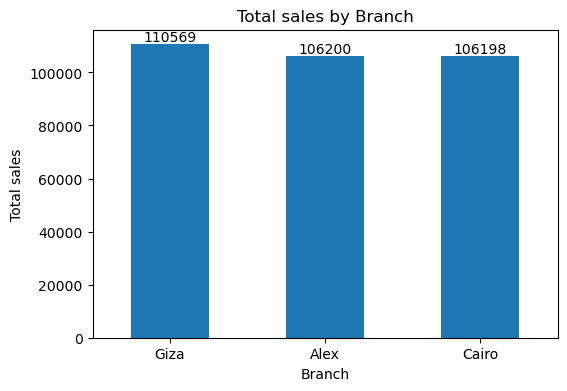

In [54]:
import matplotlib.pyplot as plt

branch_sales = df.groupby("Branch")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(6,4))

ax = branch_sales.plot(kind="bar")
plt.title("Total sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total sales")
plt.xticks(rotation=0)


# Add values on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.show()

## Business Insight

• Giza generated the highest total sales among all branches.

• Alex and Cairo recorded very similar sales performance.

• Since the difference is small, management should investigate
what practices Giza uses and determine whether they can be
implemented in the other branches.

## Business Question 4

Which customer type generates the highest total sales?


In [86]:
customer_sales = (
    df.groupby("Customer type")["Sales"].sum().sort_values(ascending=False)
)
# Display the sales totals
customer_sales

# Calculate the difference
difference = customer_sales.iloc[0] - customer_sales.iloc[1]

# Display the difference
print(f"\nDifference in total sales: {difference:.2f}")

#the percentage difference.
percentage_difference = (difference / customer_sales.iloc[1]) * 100

print(f"Percentage difference: {percentage_difference:.2f}%")


Difference in total sales: 56422.78
Percentage difference: 42.34%


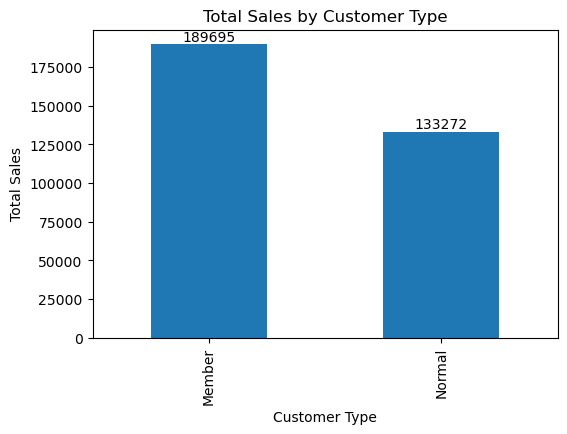

In [76]:
#plot graph
plt.figure(figsize=(6,4))
ax = customer_sales.plot(kind="bar")
plt.title("Total Sales by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Total Sales")

for container in ax.containers:
    ax.bar_label(container, fmt ="%.0f")

plt.show()


## Business Insight
* Customer type with the highest total sales: Members generated the highest total sales.
* Members generated **56,422.78** more in total sales than Normal customers,representing approximately **42.34%** higher sales. indicating that loyalty program   members contribute significantly more revenue    to the supermarket.
* This suggests that the membership program is effective in encouraging customers to spend more.
* Recommendation: Increase membership enrollment by offering discounts, reward points, birthday gifts, or exclusive promotions. Expanding the             membership program could further increase total sales and customer loyalty.


## Business Question

Which gender generates the highest total sales?

In [92]:
gender_sales = (
    df.groupby("Gender")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

#display sales total
print(gender_sales)

Gender
Female    194671.8375
Male      128294.9115
Name: Sales, dtype: float64


In [96]:
#Calculate the difference
difference = gender_sales.iloc[0]-gender_sales.iloc[1]
print(f"Difference in total sales:{difference:.2f}")

Difference in total sales:66376.93


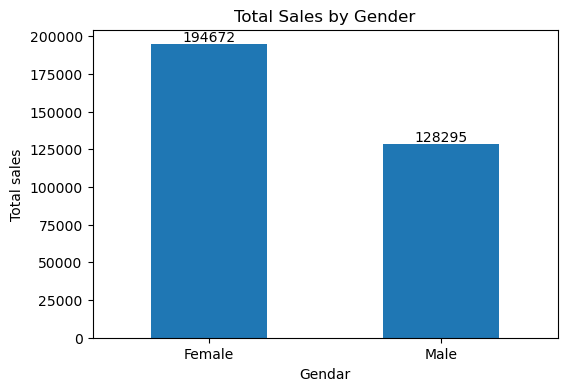

In [112]:
#plot Graph
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

ax=gender_sales.plot(kind="bar")

plt.title("Total Sales by Gender")
plt.xlabel("Gendar")
plt.ylabel("Total sales")

plt.xticks(rotation=0)

# Add values on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.show()


## Business Insight

• Customer gender with the highest total sales: Female

• Female customers generated **₦66,376.93** more in total sales than male customers.

• This suggests that female customers contribute more revenue to the supermarket and may purchase more frequently, buy higher-value products, or both.

• Recommendation: The supermarket should continue attracting female customers through targeted promotions, personalized offers, and loyalty rewards. At the same time, marketing campaigns aimed at increasing male customer spending could help balance revenue growth.

## Business Question
Which payment method generates the highest total sales?


In [132]:
# Calculating Total Sales by Payment Method
payment_sales = (
            df.groupby("Payment")["Sales"]
            .sum()
            .sort_values(ascending=False)
 )
# Display the sales totals
print(payment_sales)

Payment
Cash           112206.570
Ewallet        109993.107
Credit card    100767.072
Name: Sales, dtype: float64


In [142]:
# Calculate the difference
difference = payment_sales.iloc[0] - payment_sales.iloc[1]

#Display difference
print(f"\nDifference in total sales:{difference:.2f}")


Difference in total sales:2213.46


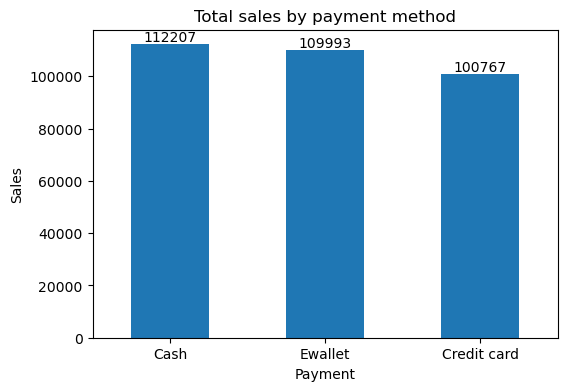

In [156]:
#plot the Graph
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))

ax = payment_sales.plot(kind="bar")

plt.title("Total sales by Payment Method")
plt.xlabel("Payment")
plt.ylabel("Sales")

plt.xticks(rotation=0)

# Add values on top of the bars
for container in ax.containers:
    ax.bar_label(container,fmt="%.0f")


plt.show()



## Business Insight
Payment method with the highest total sales: Cash.
Cash payments generated **₦2,213.46** more in total sales than Ewallet payments.
The difference between Cash and Ewallet sales is relatively small, suggesting that customers are comfortable using both payment methods. Credit card payments generated the lowest total sales among the three payment options.
Recommendation: Continue supporting all payment methods while ensuring that cash transactions remain fast and efficient. The supermarket could also encourage greater use of digital payment methods, such as Ewallet and Credit Cards, by offering cashback, discounts, or loyalty rewards to reduce cash handling and improve customer convenience.

## Business Question
**Which month generated the highest total sales?**

In [162]:
#Before analyzing months, we need to make sure the Date column is stored as a date, not as text.
df["Date"].head()

0     1/5/2019
1     3/8/2019
2     3/3/2019
3    1/27/2019
4     2/8/2019
Name: Date, dtype: object

In [166]:
#Convert the Date Column to Datetime
df["Date"] = pd.to_datetime(df["Date"])

# Check the data type
df["Date"].dtype

dtype('<M8[ns]')

In [170]:
#Create a Month Column

#Now we'll extract only the month from each date.
df["Month"]= df["Date"].dt.month_name()

# Display the first five rows
df[["Date", "Month"]].head()

,Date,Month
0,2019-01-05,January
1,2019-03-08,March
2,2019-03-03,March
3,2019-01-27,January
4,2019-02-08,February


In [182]:
#Calculate Total Sales by Month
monthly_sales = (
    df.groupby("Month")["Sales"]
    .sum()
    
)
print(monthly_sales)



Month
February     97219.374
January     116291.868
March       109455.507
Name: Sales, dtype: float64


In [184]:
#to convert it to calender order

month_order = ["January", "February", "March"]

monthly_sales = (
    df.groupby("Month")["Sales"]
      .sum()
      .reindex(month_order)
)

print(monthly_sales)

Month
January     116291.868
February     97219.374
March       109455.507
Name: Sales, dtype: float64


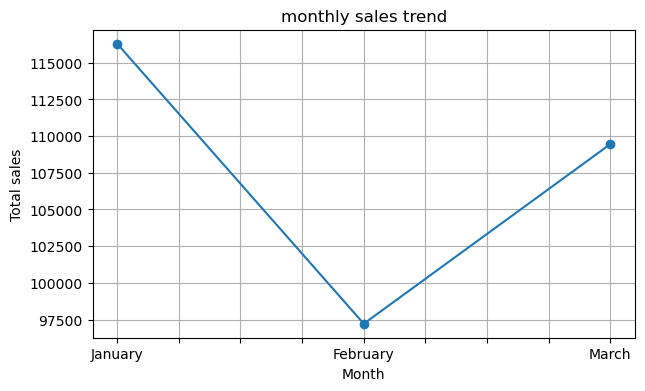

In [190]:
#Plot Monthly Sales Trend
import matplotlib.pyplot as plt
plt.figure(figsize=(7,4))

ax = monthly_sales.plot(kind="line" ,marker= "o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total sales")

plt.grid(True)

plt.show()


## Business Insight
January recorded the highest total sales with approximately 116,291.87.
February had the lowest total sales with approximately 97,219.37.
Sales increased again in March to approximately 109,455.51, showing signs of recovery after February's decline.
Recommendation: Investigate why February experienced lower sales (such as fewer promotions, seasonal demand, or lower customer traffic). Strategies used in January could be repeated in future months to maintain higher sales throughout the year.


## Business Question
**Which hour of the day generates the highest total sales?**

In [208]:
#lets make sure the time is stored as time not text
df["Time"].head()



0     1:08:00 PM
1    10:29:00 AM
2     1:23:00 PM
3     8:33:00 PM
4    10:37:00 AM
Name: Time, dtype: object

In [212]:
# Let's convert the Time column to a datetime type. 
df["Time"] = pd.to_datetime(df["Time"])

# Check the data type
df["Time"].dtype



dtype('<M8[ns]')

In [214]:
# Create Hour Column

df["Hour"] = df["Time"].dt.hour

# Display first five rows
df[["Time", "Hour"]].head()

,Time,Hour
0,2026-07-13 13:08:00,13
1,2026-07-13 10:29:00,10
2,2026-07-13 13:23:00,13
3,2026-07-13 20:33:00,20
4,2026-07-13 10:37:00,10


In [220]:
# Calculate Total Sales by Hour
hourly_sales =(
    df.groupby("Hour")["Sales"]
    .sum()
)
print(hourly_sales)

Hour
10    31421.4810
11    30377.3295
12    26065.8825
13    34723.2270
14    30828.3990
15    31179.5085
16    25226.3235
17    24445.2180
18    26030.3400
19    39699.5130
20    22969.5270
Name: Sales, dtype: float64


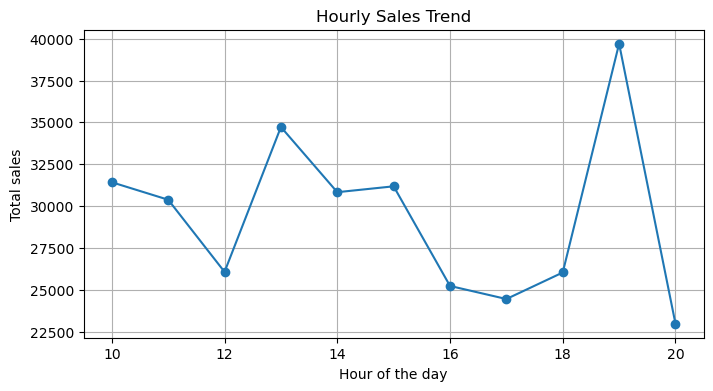

In [226]:
#Plot the Graph
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))

ax= hourly_sales.plot(kind="line",marker="o" )
plt.title("Hourly Sales Trend")
plt.xlabel("Hour of the day")
plt.ylabel("Total sales")

plt.grid(True)

plt.show()

In [230]:
# Find the hour with the highest sales
best_hour = hourly_sales.idxmax()
print(f"Best Sales Hour:{best_hour}:00" )

 Best sales Hour:19:00


## Business Insight

- The highest total sales occurred at **19:00 (7:00 PM)** with total sales of approximately **39,699.51**.
- Sales were relatively strong during the afternoon but peaked significantly in the evening.
- This suggests that customers prefer shopping after work or during evening hours.
- Recommendation: Ensure sufficient staff and product inventory are available during the evening, especially around **7:00 PM**, to maximize customer satisfaction and sales. The supermarket can also schedule promotional campaigns shortly before this peak period to attract even more customers.

**Customer Ratings Analysis**

In [236]:
# Display summary statistics for customer ratings
df["Rating"].describe()

count    1000.00000
mean        6.97270
std         1.71858
min         4.00000
25%         5.50000
50%         7.00000
75%         8.50000
max        10.00000
Name: Rating, dtype: float64

In [240]:
# Calculate the average customer rating
average_rating = df["Rating"].mean()
print(f"Average customer rating:{average_rating:.2f}")

Average customer rating:6.97


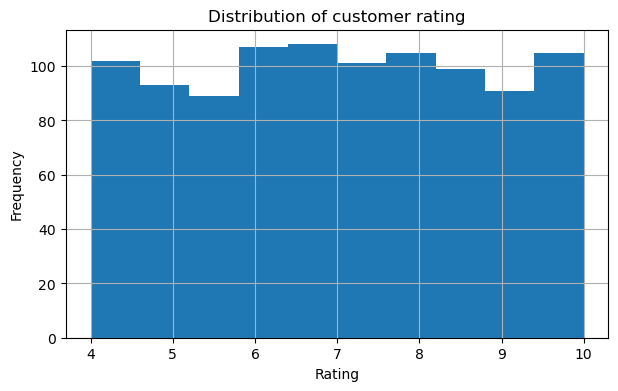

In [246]:
#import matplotlib.pyplot as plt
plt.figure(figsize=(7,4))
plt.hist(df["Rating"],bins=10)
plt.title("Distribution of customer rating")
plt.xlabel("Rating")
plt.ylabel("Frequency")

plt.grid(True)
plt.show()

In [248]:
# Highest rating
highest_rating = df["Rating"].max()

#lowest rating
lowest_rating = df["Rating"].min()

print(f"Highest rating:{highest_rating}")
print(f"Lowest rating:{lowest_rating}")


Highest rating:10.0
Lowest rating:4.0


## Business Insight
The average customer rating is **6.97 out of 10**, indicating that customers are generally satisfied with their shopping experience.
Customer ratings range from **4 to 10**, showing varying levels of satisfaction among customers.
Most customers gave ratings between **6 and 8**, suggesting that the supermarket provides a reasonably good shopping experience.
**Recommendation:** Improve customer service, product availability, and checkout efficiency to increase customer satisfaction and encourage more customers to give higher ratings.



## Business Question

Is there a relationship between customer ratings and sales?

Correlation tells us whether two numeric variables move together.

Correlation = 1 → Perfect positive relationship

Correlation close to 0 → Little or no linear relationship

Correlation = -1 → Perfect negative relationship

For this supermarket dataset, we'll examine whether customers who spend more tend to give higher ratings.


In [258]:
# Calculate correlation between Sales and Rating
correlation = df["Sales"].corr(df["Rating"])
print(f"Correlation Between Sales and Rating:{correlation:.2f}")
                               

Correlation Between Sales and Rating:-0.04


## Create a Scatter Plot

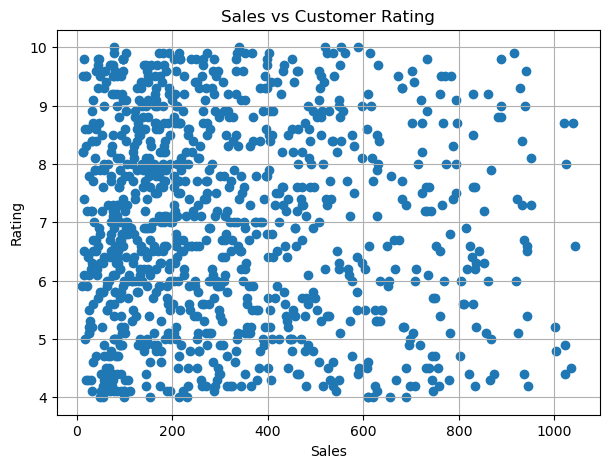

In [267]:
# Plot the relationship between Sales and Rating
import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
           
plt.scatter(df["Sales"] , df["Rating"]) 
plt.title("Sales vs Customer Rating")
plt.xlabel("Sales")
plt.ylabel("Rating")

plt.grid(True)

plt.show()


## Business Insight

The correlation between Sales and Customer Rating is **-0.04**, indicating almost no relationship between the two variables. This means that customers who spend more do not necessarily give higher ratings, and customers who spend less do not necessarily give lower ratings. The scatter plot also shows no clear pattern, confirming that customer spending does not significantly influence customer ratings.

**Recommendation:** Focus on improving factors that directly affect customer satisfaction, such as customer service, product quality, product availability, and checkout efficiency, rather than assuming that higher spending leads to higher customer satisfaction.